In [3]:
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sentence_transformers.util import cos_sim
import gensim.downloader as api

# Using sentence_transformers package of python

In [7]:
model = SentenceTransformer("all-MiniLM-L6-v2")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4413.88it/s]


In [4]:
sentences = [
    'I am Iqra Afzal',
    'I love learning new things',
    'Japan is an advanced country',
    'We should keep trying new things',
    'Fruits are good for health',
    'I bought one dozen bananas yesterday',
    'An apple a day keeps the doctor away'
]

In [44]:
embeddings = model.encode(sentences)

In [45]:
embeddings.shape

(7, 384)

# Let's see the similarities

In [46]:
similarities = cos_sim(embeddings, embeddings)

In [47]:
print(similarities)

tensor([[1.0000, 0.1765, 0.1586, 0.1078, 0.1190, 0.0624, 0.0802],
        [0.1765, 1.0000, 0.0899, 0.4353, 0.0779, 0.1996, 0.0871],
        [0.1586, 0.0899, 1.0000, 0.0744, 0.1709, 0.1028, 0.0401],
        [0.1078, 0.4353, 0.0744, 1.0000, 0.0615, 0.1190, 0.0466],
        [0.1190, 0.0779, 0.1709, 0.0615, 1.0000, 0.3933, 0.4541],
        [0.0624, 0.1996, 0.1028, 0.1190, 0.3933, 1.0000, 0.2647],
        [0.0802, 0.0871, 0.0401, 0.0466, 0.4541, 0.2647, 1.0000]])


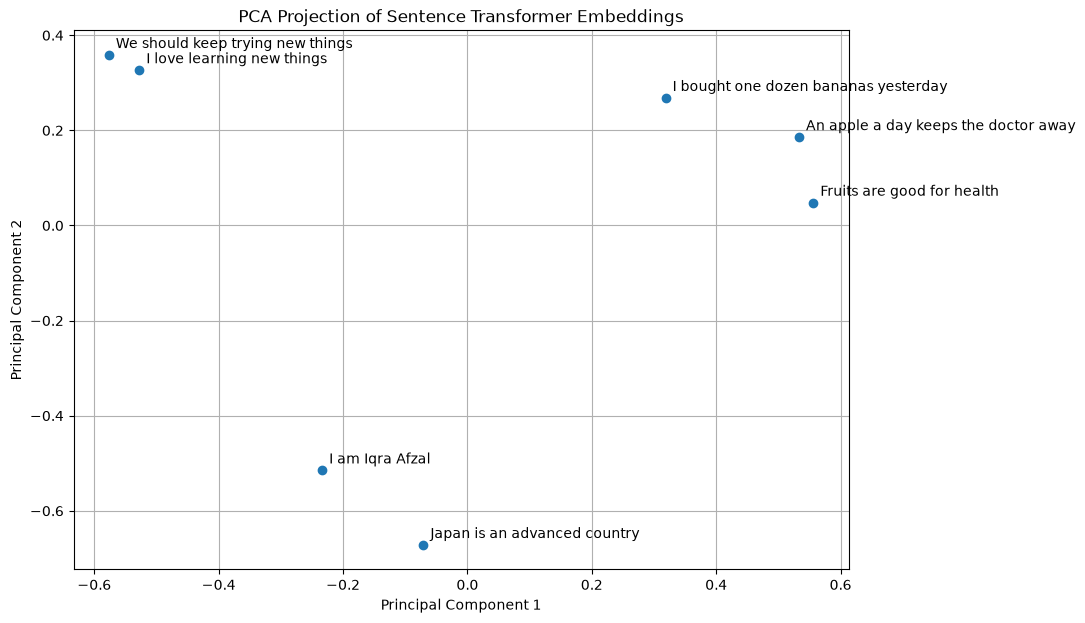

In [48]:
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)

plt.figure(figsize=(10,7))
plt.scatter(
    embeddings_2d[:, 0],
    embeddings_2d[:, 1]
)

# Label each point with its sentence
for i, sentence in enumerate(sentences):
    plt.annotate(
        sentence,
        (embeddings_2d[i, 0], embeddings_2d[i, 1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection of Sentence Transformer Embeddings")
plt.grid(True)
plt.show()